# Workers within one recording

`compute(n_jobs=k)` spreads the SPIs of one recording over $k$ processes. SPIs that share a cached intermediate (one covariance fit, one cross-spectrum) form a single task and stay on one worker; an SPI is never split across workers. Every stochastic estimator carries its own fixed seed, so the table does not depend on $k$, on the start method, or on what ran before.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.simplefilter("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"      # spawned workers too

BENCH = Path("../../bench/pair_sampling"); sys.path.insert(0, str(BENCH))
import validate as V
from pyspi import _parallel
from pyspi.calculator import Calculator
from pyspi.data import Data

plt = V.figure_style(backend=None)
plt.rcParams["figure.dpi"] = 110
RESULTS, GADI = BENCH / "results", BENCH / "results" / "gadi-smoke"

## 1. Same table for any number of workers

`benchmarked_p90` (289 SPIs) on a small fixture where six SPIs fail. At this size starting the pool costs more than it saves; the comparison is of values, missing entries and recorded failures.

In [2]:
FIXTURE = "../../tests/data/fixtures/kuramoto_M7_T100.npy"

def run(n_jobs, seed):
    np.random.seed(seed)                     # the global stream must not matter
    calc = Calculator(dataset=Data(data=FIXTURE, dim_order="sp"), config="benchmarked_p90", verbose=False)
    start = time.perf_counter()
    calc.compute(n_jobs=n_jobs, progress=False)
    return calc, time.perf_counter() - start

runs = {k: run(k, seed=k) for k in (1, 2, 4)}
ref = runs[1][0]
pd.DataFrame([{"n_jobs": k, "seconds": round(t, 1),
               "table identical": np.array_equal(c.table.to_numpy(float), ref.table.to_numpy(float), equal_nan=True),
               "failed SPIs": len(c.errors), "same failures": c.errors == ref.errors}
              for k, (c, t) in runs.items()])

,n_jobs,seconds,table identical,failed SPIs,same failures
0,1,5.2,True,6,True
1,2,8.3,True,6,True
2,4,8.0,True,6,True


## 2. What a worker is handed

Tasks are the unit of scheduling. The longest one bounds the wall time however many workers there are.

In [3]:
tasks = _parallel.build_tasks(list(ref.spis), ref.spis)
sizes = pd.Series([len(t) for t in tasks])
print(f"{len(ref.spis)} SPIs in {len(tasks)} tasks: {int((sizes == 1).sum())} single-SPI tasks, "
      f"{int((sizes > 1).sum())} shared-cache tasks of {sizes[sizes > 1].min()}-{sizes.max()} SPIs")

289 SPIs in 162 tasks: 132 single-SPI tasks, 30 shared-cache tasks of 2-24 SPIs

## 3. Speed-up and memory, $M=20$, $T=1000$ (local, spawned workers)

Left: wall time against the ideal $1/k$. Middle: the summed time of the SPIs themselves; it grows with $k$, so each SPI runs slower beside others. Right: peak resident memory; a parallel run holds the parent plus up to $k$ workers.

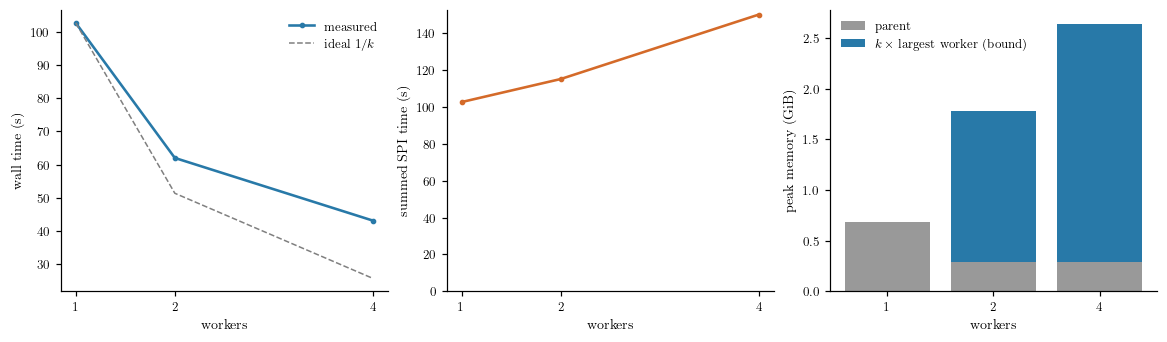

,n_jobs,wall_s,speedup,spi_seconds,values_sha256
0,1,102.7,1.00,102.7,891e27776b18e475
1,2,62.0,1.66,115.2,891e27776b18e475
2,4,43.1,2.38,150.2,891e27776b18e475


In [4]:
w = pd.read_csv(RESULTS / "workers.csv").query("n_pairs == 'all'")
fig, (a, b, c) = plt.subplots(1, 3, figsize=(10.5, 3))
a.plot(w.n_jobs, w.wall_s, "o-", color="#2879a8", label="measured")
a.plot(w.n_jobs, w.wall_s.iloc[0] / w.n_jobs, color=".5", ls="--", lw=1, label=r"ideal $1/k$")
a.set(xlabel="workers", ylabel="wall time (s)", xticks=w.n_jobs); a.legend()
b.plot(w.n_jobs, w.spi_seconds, "o-", color="#d46a29")
b.set(xlabel="workers", ylabel="summed SPI time (s)", xticks=w.n_jobs, ylim=(0, None))
c.bar(w.n_jobs.astype(str), w.parent_rss_mib / 1024, color=".6", label="parent")
c.bar(w.n_jobs.astype(str), w.n_jobs.where(w.n_jobs > 1, 0) * w.worker_rss_mib / 1024,
      bottom=w.parent_rss_mib / 1024, color="#2879a8", label=r"$k\,\times$ largest worker (bound)")
c.set(xlabel="workers", ylabel="peak memory (GiB)"); c.legend()
plt.show()
w.assign(speedup=(w.wall_s.iloc[0] / w.wall_s).round(2))[["n_jobs", "wall_s", "speedup", "spi_seconds", "values_sha256"]]

## 4. One MEG recording on Gadi, $M=64$, $T=1000$, full table

Forked workers on a Cascade Lake node, each job bound by PBS to exactly $k$ cores. *Schedule* replays the one-worker per-SPI timings through the task order: the speed-up the existing tasks allow if no SPI ran slower beside others. At eight workers it is already limited by the longest task (middle panel).

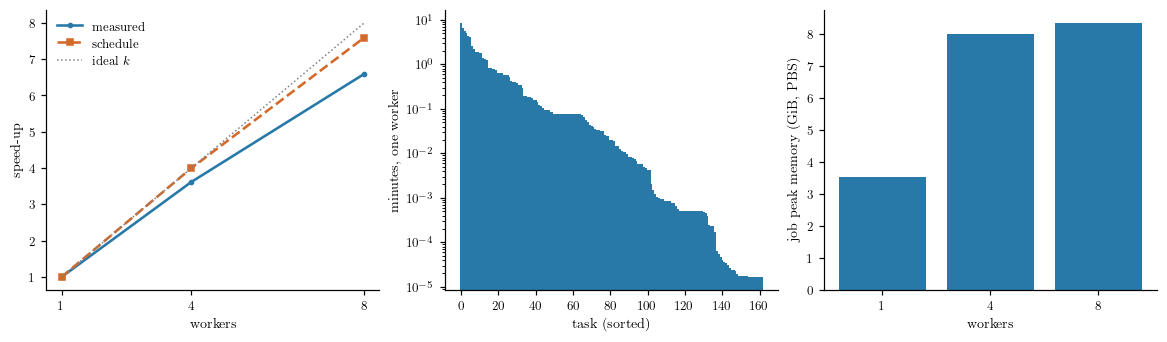

,run,n_jobs,bound_cores,start_method,wall_hours,speedup,schedule,spi_seconds,pbs_mem_gib,failed
0,m64-dense-j1,1,1,None,1.08,1.00,1.00,3893.33,3.51,0
1,m64-dense-j4,4,4,fork,0.30,3.62,4.00,4300.54,7.97,0
2,m64-dense-j8,8,8,fork,0.16,6.59,7.59,4294.51,8.32,0


tables identical across worker counts:

True

against the r7 full extraction: 274 identical, 0 rounding, 15 changed in r8, 0 different, 0 failed in either

In [5]:
def makespan(costs, k):
    # Wall time when k workers take tasks in order, each as it frees up.
    free = np.zeros(k)
    for cost in costs:
        free[free.argmin()] += cost
    return free.max()

if (GADI / "summary.json").exists():
    summary = json.loads((GADI / "summary.json").read_text())
    g = pd.DataFrame(summary["runs"]).query("M == 64").sort_values("n_jobs").reset_index(drop=True)
    timings = json.loads((GADI / "m64-dense-j1" / "report.json").read_text())["timings"]
    costs = [sum(timings[k] for k in task) for task in tasks]
    g["speedup"] = g.wall_seconds.iloc[0] / g.wall_seconds
    g["schedule"] = [sum(costs) / makespan(costs, k) for k in g.n_jobs]

    fig, (a, b, c) = plt.subplots(1, 3, figsize=(10.5, 3))
    a.plot(g.n_jobs, g.speedup, "o-", color="#2879a8", label="measured")
    a.plot(g.n_jobs, g.schedule, "s--", color="#d46a29", ms=3.5, label="schedule")
    a.plot(g.n_jobs, g.n_jobs, color=".5", ls=":", lw=1, label=r"ideal $k$")
    a.set(xlabel="workers", ylabel="speed-up", xticks=g.n_jobs); a.legend()
    order = np.sort(costs)[::-1]
    b.bar(range(len(order)), order / 60, color="#2879a8", width=1)
    b.set(xlabel="task (sorted)", ylabel="minutes, one worker", yscale="log")
    c.bar(g.n_jobs.astype(str), g.pbs_mem_gib, color="#2879a8")
    c.set(xlabel="workers", ylabel="job peak memory (GiB, PBS)")
    plt.show()
    display(g[["run", "n_jobs", "bound_cores", "start_method", "wall_hours", "speedup", "schedule",
               "spi_seconds", "pbs_mem_gib", "failed"]].round(2))
    print("tables identical across worker counts:", summary["identical_across_workers"]["m64-dense"])
    print(summary["m64_vs_dense"])

## 5. Threads

Workers start with these variables at 1 and with `threadpoolctl` limits on BLAS and OpenMP; the caller's values are restored when the pool closes. `available_cores()` reads the affinity mask, so under a scheduler it is the cores granted, and `compute` warns when `n_jobs` times the thread count exceeds it.

In [6]:
_parallel._BLAS_ENV_VARS, _parallel.available_cores()

(('OMP_NUM_THREADS',
  'OPENBLAS_NUM_THREADS',
  'MKL_NUM_THREADS',
  'VECLIB_MAXIMUM_THREADS',
  'NUMEXPR_NUM_THREADS',
  'NUMBA_NUM_THREADS'),
 10)